# 12 — Controlled YOLOX geometric-augmentation experiment

Run sections in order with the CUDA environment from notebook 08. This notebook DOES train when you run its training section. It runs two ten-epoch fine-tunes from the same current best checkpoint: a brightness/contrast control and a brightness/contrast plus geometry candidate. Both use the same seed, data order, optimiser, learning rate and epoch budget. This distinguishes augmentation from simply training longer.

Existing prepared train/validation/test splits, baseline checkpoints, deployment ONNX, and latest_run.json remain unchanged. No QA images or validation/test designs enter training. New artefacts live under training/runs/yolox_geometry_experiments/. A separate pointer identifies the completed experiment for notebooks 13–14.

The geometry recipe modestly rotates, scales, translates and applies perspective to the whole letterboxed image without cropping content away. Box corners undergo the same homography; their enclosing rectangle becomes the new target. This is conservative because the source annotations are boxes, not document polygons. Preview the transformed boxes before training.

Default runtime is two ten-epoch runs; use notebook 08's timings as a rough guide. All 40 baseline epochs are reused through the frozen initial checkpoint. Training has not been started by the assistant.

In [12]:
from pathlib import Path
from collections import Counter
import sys
import json
import hashlib
import time
import random
import html

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, HTML

PROJECT = Path("/home/joe/PycharmProjects/id-capture")
SOURCE = PROJECT / "training/vendor/YOLOX"
for directory in (str(PROJECT), str(SOURCE)):
    if directory not in sys.path:
        sys.path.insert(0, directory)
from training.yolox_workflow import (
    make_model, predict_records, summarize, audit, save_json,
    letterbox, show_progress, NAMES,
)

def sha256_file(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

def table(rows):
    if not rows:
        print("No rows.")
        return
    columns = list(rows[0])
    head = "".join(f"<th>{html.escape(str(c))}</th>" for c in columns)
    body = "".join(
        "<tr>" + "".join(f"<td>{html.escape(str(row[c]))}</td>" for c in columns) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

assert torch.cuda.is_available(), "Select the CUDA environment used in notebook 08."
DATA = PROJECT / "training/data/yolox_all_sources"
baseline_pointer = json.loads((DATA / "latest_run.json").read_text())
MANIFEST_PATH = Path(baseline_pointer["manifest"])
manifest = json.loads(MANIFEST_PATH.read_text())
audit(manifest["records"])
BASELINE = Path(baseline_pointer["best"])
BASELINE_HASH = sha256_file(BASELINE)
MANIFEST_HASH = sha256_file(MANIFEST_PATH)
train_records = [r for r in manifest["records"] if r["split"] == "train"]
val_records = [r for r in manifest["records"] if r["split"] == "val"]
EPOCHS, BATCH, SIZE, SEED, LR = 10, 16, baseline_pointer["size"], 42, 0.00005
EXPERIMENT_ROOT = PROJECT / "training/runs/yolox_geometry_experiments"
print("GPU:", torch.cuda.get_device_name(0))
print("Frozen baseline:", BASELINE)
print("Two runs:", EPOCHS, "epochs each | batch:", BATCH, "| size:", SIZE, "| LR:", LR)


train 13100 {('midv500', 'none'): 4292, ('midv500', 'driving_licence'): 2362, ('midv500', 'passport'): 2346, ('midv2019', 'none'): 1680, ('midv2019', 'driving_licence'): 960, ('midv2019', 'passport'): 960, ('midv2020', 'none'): 200, ('midv2020', 'passport'): 300}
val 4400 {('midv500', 'none'): 1511, ('midv500', 'passport'): 890, ('midv500', 'driving_licence'): 599, ('midv2019', 'none'): 600, ('midv2019', 'passport'): 360, ('midv2019', 'driving_licence'): 240, ('midv2020', 'none'): 100, ('midv2020', 'passport'): 100}
test 4500 {('midv500', 'passport'): 884, ('midv500', 'none'): 1537, ('midv500', 'driving_licence'): 579, ('midv2019', 'passport'): 360, ('midv2019', 'driving_licence'): 240, ('midv2019', 'none'): 600, ('midv2020', 'none'): 300}
PASS: no document design crosses splits; all images exist.
GPU: NVIDIA GeForce RTX 5060 Ti
Frozen baseline: /home/joe/PycharmProjects/id-capture/training/runs/yolox_tiny_20261021_164408_054475/best.pth
Two runs: 10 epochs each | batch: 16 | size: 416

## Geometry and label transformation
No flips, mosaic, negative oversampling, or new documents are introduced in this experiment.

In [13]:
from torch.utils.data import Dataset, DataLoader

GEOMETRY = dict(degrees=15.0, scale_min=0.75, scale_max=1.0, perspective_jitter=0.035)

def project_box(box, matrix, size):
    x1, y1, x2, y2 = box
    corners = np.array([[x1,y1], [x2,y1], [x2,y2], [x1,y2]], dtype=np.float32)
    warped = cv2.perspectiveTransform(corners[None], matrix)[0]
    out = np.r_[warped.min(axis=0), warped.max(axis=0)]
    out[[0, 2]] = out[[0, 2]].clip(0, size)
    out[[1, 3]] = out[[1, 3]].clip(0, size)
    return out

def geometric_warp(image, box, rng, config=GEOMETRY):
    size = image.shape[0]
    assert image.shape == (size, size, 3)
    src = np.array([[0,0], [size-1,0], [size-1,size-1], [0,size-1]], dtype=np.float32)
    angle = np.deg2rad(rng.uniform(-config["degrees"], config["degrees"]))
    rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    dst = (src - (size - 1) / 2) @ rotation.T
    dst *= rng.uniform(config["scale_min"], config["scale_max"])
    jitter = size * config["perspective_jitter"]
    dst += rng.uniform(-jitter, jitter, (4, 2))
    # Keep the entire source frame inside the output, avoiding label loss from cropping.
    span = np.ptp(dst, axis=0)
    dst *= min(1.0, (size - 7) / float(span.max()))
    lo, hi = dst.min(axis=0), dst.max(axis=0)
    offset = np.array([rng.uniform(2 - lo[i], size - 3 - hi[i]) for i in range(2)])
    dst = (dst + offset).astype(np.float32)
    if not cv2.isContourConvex(dst):
        return image, box
    matrix = cv2.getPerspectiveTransform(src, dst)
    candidate = None if box is None else project_box(box, matrix, size)
    if candidate is not None and (
        not np.isfinite(candidate).all() or np.any(candidate[2:] - candidate[:2] < 4)
    ):
        return image, box  # Preserve the original positive rather than inventing a negative.
    warped = cv2.warpPerspective(
        image, matrix, (size, size), flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT, borderValue=(114,114,114),
    )
    return warped, candidate

class ExperimentDataset(Dataset):
    def __init__(self, records, size, geometry, seed):
        self.records, self.size, self.geometry = records, size, geometry
        # Geometry does not consume photometric/shuffle random numbers from the control.
        self.photo_rng = np.random.default_rng(seed)
        self.geometry_rng = np.random.default_rng(seed + 1000)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        assert record["split"] == "train"
        frame = cv2.imread(record["image"])
        if frame is None:
            raise ValueError(record["image"])
        frame = np.clip(
            frame.astype(np.float32) * self.photo_rng.uniform(0.75, 1.25)
            + self.photo_rng.uniform(-15, 15), 0, 255,
        ).astype(np.uint8)
        tensor, ratio = letterbox(frame, self.size)
        canvas = tensor.transpose(1,2,0).astype(np.uint8)
        box = None if record["class"] is None else np.array(record["box"], dtype=float) * ratio
        if self.geometry:
            canvas, box = geometric_warp(canvas, box, self.geometry_rng)
        target = np.zeros((1,5), dtype=np.float32)
        if box is not None:
            x1,y1,x2,y2 = box
            assert np.isfinite(box).all() and x2 > x1 and y2 > y1
            target[0] = [record["class"], (x1+x2)/2, (y1+y2)/2, x2-x1, y2-y1]
        tensor = np.ascontiguousarray(canvas.transpose(2,0,1), dtype=np.float32)
        return torch.from_numpy(tensor), torch.from_numpy(target)


## Sanity checks and preview
Run before training. Confirm the positive boxes still contain the document. Negative images deliberately have no target boxes.

PASS: identity, positive geometry and negative-label checks.


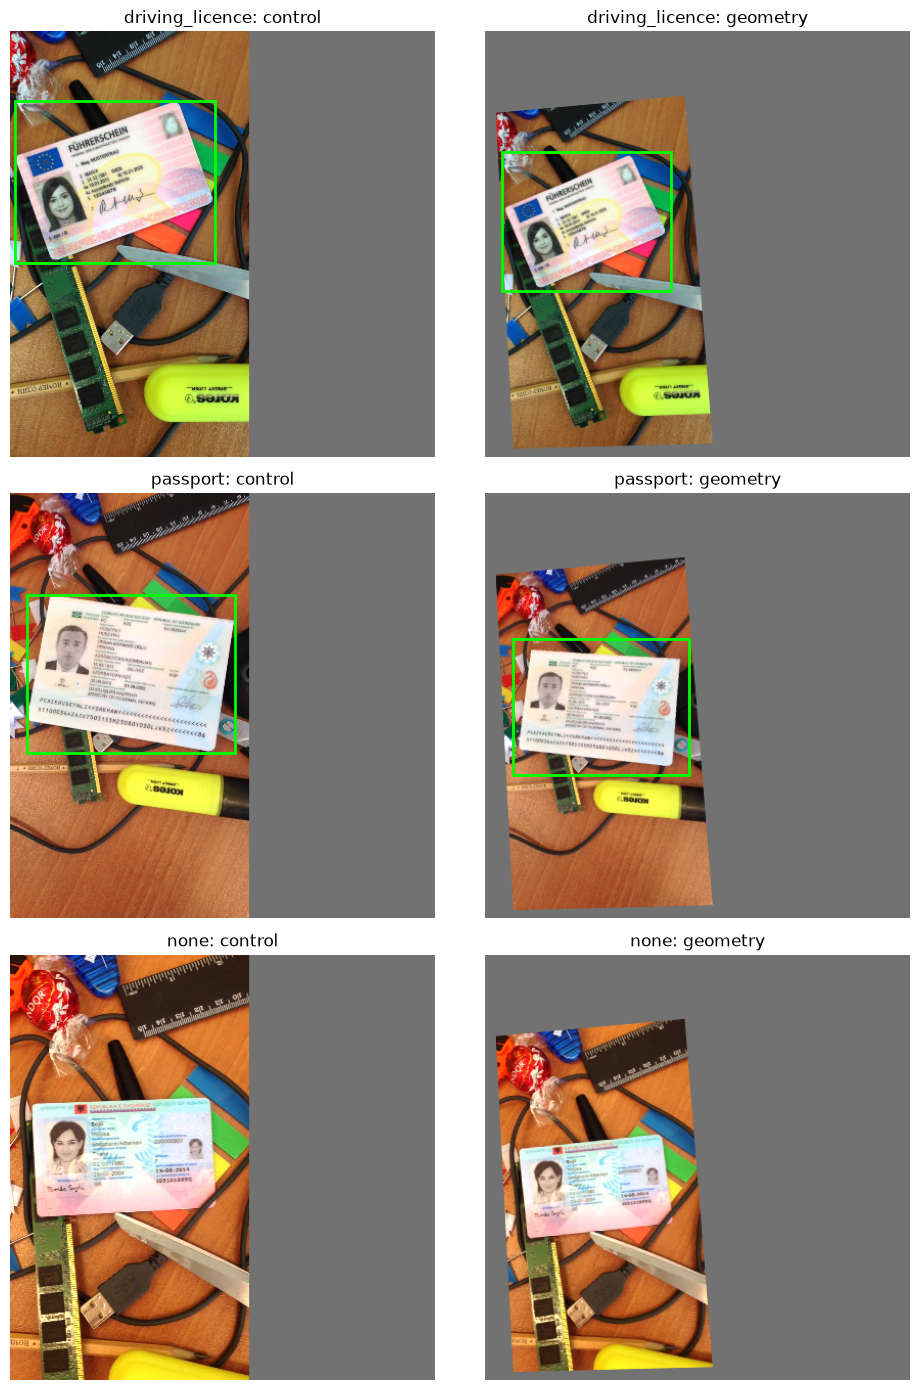

In [14]:
identity = np.eye(3, dtype=np.float32)
np.testing.assert_allclose(project_box([20,30,100,140], identity, SIZE), [20,30,100,140])
check_image = np.full((SIZE,SIZE,3), 114, dtype=np.uint8)
for seed in range(50):
    warped, box = geometric_warp(
        check_image, np.array([30,40,SIZE-30,SIZE-40], dtype=float),
        np.random.default_rng(seed),
    )
    assert warped.shape == check_image.shape
    assert np.isfinite(box).all() and np.all(box[2:] > box[:2])
    assert np.all(box >= 0) and np.all(box <= SIZE)
    _, empty = geometric_warp(check_image, None, np.random.default_rng(seed))
    assert empty is None
print("PASS: identity, positive geometry and negative-label checks.")

preview_records = [
    next(r for r in train_records if r["class"] == cls) for cls in (0,1,None)
]
fig, axes = plt.subplots(3,2,figsize=(10,14))
for row, record in enumerate(preview_records):
    for column, enabled in enumerate((False,True)):
        image, target = ExperimentDataset([record], SIZE, enabled, SEED)[0]
        ax = axes[row,column]
        ax.imshow(image.numpy().transpose(1,2,0)[:,:,::-1].astype(np.uint8))
        if record["class"] is not None:
            _, cx,cy,w,h = target.numpy()[0]
            ax.add_patch(Rectangle((cx-w/2,cy-h/2),w,h,fill=False,edgecolor="lime",linewidth=2))
        label = "none" if record["class"] is None else NAMES[record["class"]]
        ax.set_title(f"{label}: " + ("geometry" if enabled else "control"))
        ax.axis("off")
plt.tight_layout()
plt.show()
plt.close(fig)


## Training function
Defining this cell does not start training. Both arms start from the frozen baseline with fresh optimisers. Best checkpoints use validation only; notebook 13 independently calibrates thresholds.

In [15]:
def train_arm(name, use_geometry):
    import gc
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    arm_dir = EXPERIMENT / name
    arm_dir.mkdir(exist_ok=False)
    config = dict(
        arm=name, geometry=GEOMETRY if use_geometry else None,
        epochs=EPOCHS, batch=BATCH, size=SIZE, seed=SEED, learning_rate=LR,
        initial_checkpoint=str(BASELINE), initial_sha256=BASELINE_HASH,
        manifest_sha256=MANIFEST_HASH, selection="mean recall minus negative FP at 0.25",
        photometric="brightness x[0.75,1.25] plus contrast offset [-15,15]",
    )
    save_json(arm_dir / "config.json", config)
    model = make_model(BASELINE).cuda()
    dataset = ExperimentDataset(train_records, SIZE, use_geometry, SEED)
    loader = DataLoader(
        dataset, batch_size=BATCH, shuffle=True, num_workers=0, pin_memory=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0005)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS, eta_min=LR/20)
    scaler = torch.amp.GradScaler("cuda")
    history, best_score = [], -float("inf")
    started = time.perf_counter()
    try:
        for epoch in range(EPOCHS):
            model.train()
            loss_sum = 0.0
            for step, (images, targets) in enumerate(loader, 1):
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast("cuda"):
                    losses = model(images.cuda(non_blocking=True), targets.cuda(non_blocking=True))
                    loss = losses["total_loss"]
                if not torch.isfinite(loss).item():
                    raise RuntimeError(f"{name}: nonfinite loss")
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
                scaler.step(optimizer)
                scaler.update()
                loss_sum += loss.item()
                if step % 100 == 0 or step == len(loader):
                    show_progress(
                        f"{name}: epoch {epoch+1}/{EPOCHS}, batch {step}/{len(loader)}",
                        epoch + 0.9 * step/len(loader), EPOCHS, started,
                    )
            scheduler.step()
            predictions = predict_records(model, val_records, SIZE, BATCH, 0.25)
            metric = summarize(val_records, predictions, 0.25)[0]
            score = (metric["licence_recall"] + metric["passport_recall"])/2 - metric["negative_fp"]
            row = dict(epoch=epoch+1, loss=loss_sum/len(loader), score=score, **metric)
            history.append(row)
            print(name, row, flush=True)
            state = dict(
                model=model.state_dict(), optimizer=optimizer.state_dict(),
                scheduler=scheduler.state_dict(), scaler=scaler.state_dict(),
                epoch=epoch+1, config=config,
            )
            torch.save(state, arm_dir / "last.pth")
            if score > best_score:
                torch.save(state, arm_dir / "best.pth")
                best_score = score
            save_json(arm_dir / "history.json", history)
            del predictions
            show_progress(name, epoch+1, EPOCHS, started, finished=epoch+1 == EPOCHS)
        save_json(arm_dir / "completed.json", dict(epochs=EPOCHS, best_score=best_score))
    finally:
        del model, loader, optimizer, scaler
        gc.collect()
        torch.cuda.empty_cache()
    return str(arm_dir / "best.pth")


## Run both arms and save the completed-experiment pointer

This cell starts training immediately. Rerunning it creates a new experiment, never overwriting an existing run. A failed or partial run does not replace the latest completed pointer. Test images and QA fixtures are not evaluated here.

In [16]:
from datetime import datetime

assert EPOCHS > 0 and BATCH > 0
assert sha256_file(BASELINE) == BASELINE_HASH
assert sha256_file(MANIFEST_PATH) == MANIFEST_HASH
EXPERIMENT = EXPERIMENT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
EXPERIMENT.mkdir(parents=True, exist_ok=False)
experiment_config = dict(
    experiment=str(EXPERIMENT), baseline=str(BASELINE), baseline_sha256=BASELINE_HASH,
    manifest=str(MANIFEST_PATH), manifest_sha256=MANIFEST_HASH,
    size=SIZE, epochs=EPOCHS, batch=BATCH, seed=SEED, learning_rate=LR,
    geometry=GEOMETRY,
)
save_json(EXPERIMENT / "experiment.json", experiment_config)
control_best = train_arm("control", False)
geometry_best = train_arm("geometry", True)
assert sha256_file(BASELINE) == BASELINE_HASH
assert sha256_file(MANIFEST_PATH) == MANIFEST_HASH
completed = dict(
    **experiment_config,
    checkpoints={"Baseline": str(BASELINE), "Control": control_best, "Geometry": geometry_best},
)
save_json(EXPERIMENT / "completed.json", completed)
save_json(EXPERIMENT_ROOT / "latest_completed.json", completed)
print("Both runs completed:", EXPERIMENT)
print("Next: notebook 13. The app still uses the existing exported model.")


Loaded pretrained tensors: 462 | New class-head tensors: 0
control: epoch 1/10, batch 100/819 | 1.1% | Elapsed 0:00:54 | Remaining 1:21:09 | Estimated finish 2026-10-22 18:25:51 BST
control: epoch 1/10, batch 200/819 | 2.2% | Elapsed 0:01:20 | Remaining 0:59:28 | Estimated finish 2026-10-22 18:04:36 BST
control: epoch 1/10, batch 300/819 | 3.3% | Elapsed 0:01:38 | Remaining 0:48:20 | Estimated finish 2026-10-22 17:53:47 BST
control: epoch 1/10, batch 400/819 | 4.4% | Elapsed 0:01:57 | Remaining 0:42:33 | Estimated finish 2026-10-22 17:48:18 BST
control: epoch 1/10, batch 500/819 | 5.5% | Elapsed 0:02:15 | Remaining 0:38:56 | Estimated finish 2026-10-22 17:45:00 BST
control: epoch 1/10, batch 600/819 | 6.6% | Elapsed 0:02:34 | Remaining 0:36:25 | Estimated finish 2026-10-22 17:42:48 BST
control: epoch 1/10, batch 700/819 | 7.7% | Elapsed 0:02:52 | Remaining 0:34:32 | Estimated finish 2026-10-22 17:41:13 BST
control: epoch 1/10, batch 800/819 | 8.8% | Elapsed 0:03:11 | Remaining 0:33:02 